# Nuages de mots

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/joelmufaume/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [21]:
# Stopwords (idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem",
       "agence", "rue","ans", "bon", "dés", "demande", "très", "ecr"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [16]:
# Choisir une année
year = 1913

In [17]:
# Lister les fichiers de cette année
data_path = '../data'
txt_path = '../data/txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [18]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [19]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [20]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"« ocTumœ ms' l'B *S O IK i /'ihavffsurménmlelsn, 99 Ajtsas, pari. ang!..franc. «an)., dés. place, maison îprîÿêe,environs Bruxelles, présente par parents. R. Copin»'Mon Rêve, Leffin- ghe lei-Ostenûo. "

In [22]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../data/tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [23]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"« ocTumœ ms' l'B *S O IK i /'ihavffsurménmlelsn, 99 Ajtsas, pari. ang!..franc. «an)., dés. place, maison îprîÿêe,environs Bruxelles, présente par parents. R. Copin»'Mon Rêve, Leffin- ghe lei-Ostenûo. 0915 J - eune architecte diplômé ayant pratiqué niusieu’* Apnées, cherche emploi & jBrux ou en province. Ecr. C. B. F.. Ag. Rossel- 4529 J ne boni, 26 ans, prop.. 6. cert., réf. 1er ord. deœ. emploi pour courses. •J. L. K. 7. lmp. l'Hôpital. 2778 M o ns. seul dem. place conc., act., hoo. Ecr. B. L. "

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [24]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [25]:
clean_text(year, folder=temp_path)

'Output has been written in ../data/tmp/1913_clean.txt!'

In [27]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'OCTUMŒ IHAVFFSURMÉNMLELSN AJTSAS PARI ANG FRANC PLACE MAISON ÎPRÎŸÊE ENVIRONS BRUXELLES PRÉSENTE PARENTS COPIN RÊVE LEFFIN GHE LEI OSTENÛO EUNE ARCHITECTE DIPLÔMÉ PRATIQUÉ NIUSIEU APNÉES CHERCHE EMPLOI JBRUX PROVINCE BONI PROP CERT RÉF ORD DEŒ EMPLOI COURSES LMP HÔPITAL SEUL PLACE CONC ACT HOO OFFRE PRIME DEL QUICONQUE PROCURERA POSITION STABLE MONSIEUR HONORABLE INSTRUIT LANGUES FÉRCHCES EXCELL ROSSAI MÉN OONE MARI EMPL DÉFILERA SERV CERTLF SAINTE MARIE FEM FLAMANDE DCM JOURN DTL IIENS FOIS FEM'

## Nuage de mots

### Afficher les termes les plus fréquents


In [28]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('BRUXELLES', 1037), ('MAISON', 822), ('PRIX', 764), ('FILLE', 629), ('PLACE', 582), ('LOUER', 561), ('HEURES', 505), ('GRAND', 481), ('VEND', 464), ('NORD', 452)]


### Créer, stocker et afficher le nuage de mots

Matplotlib is building the font cache; this may take a moment.


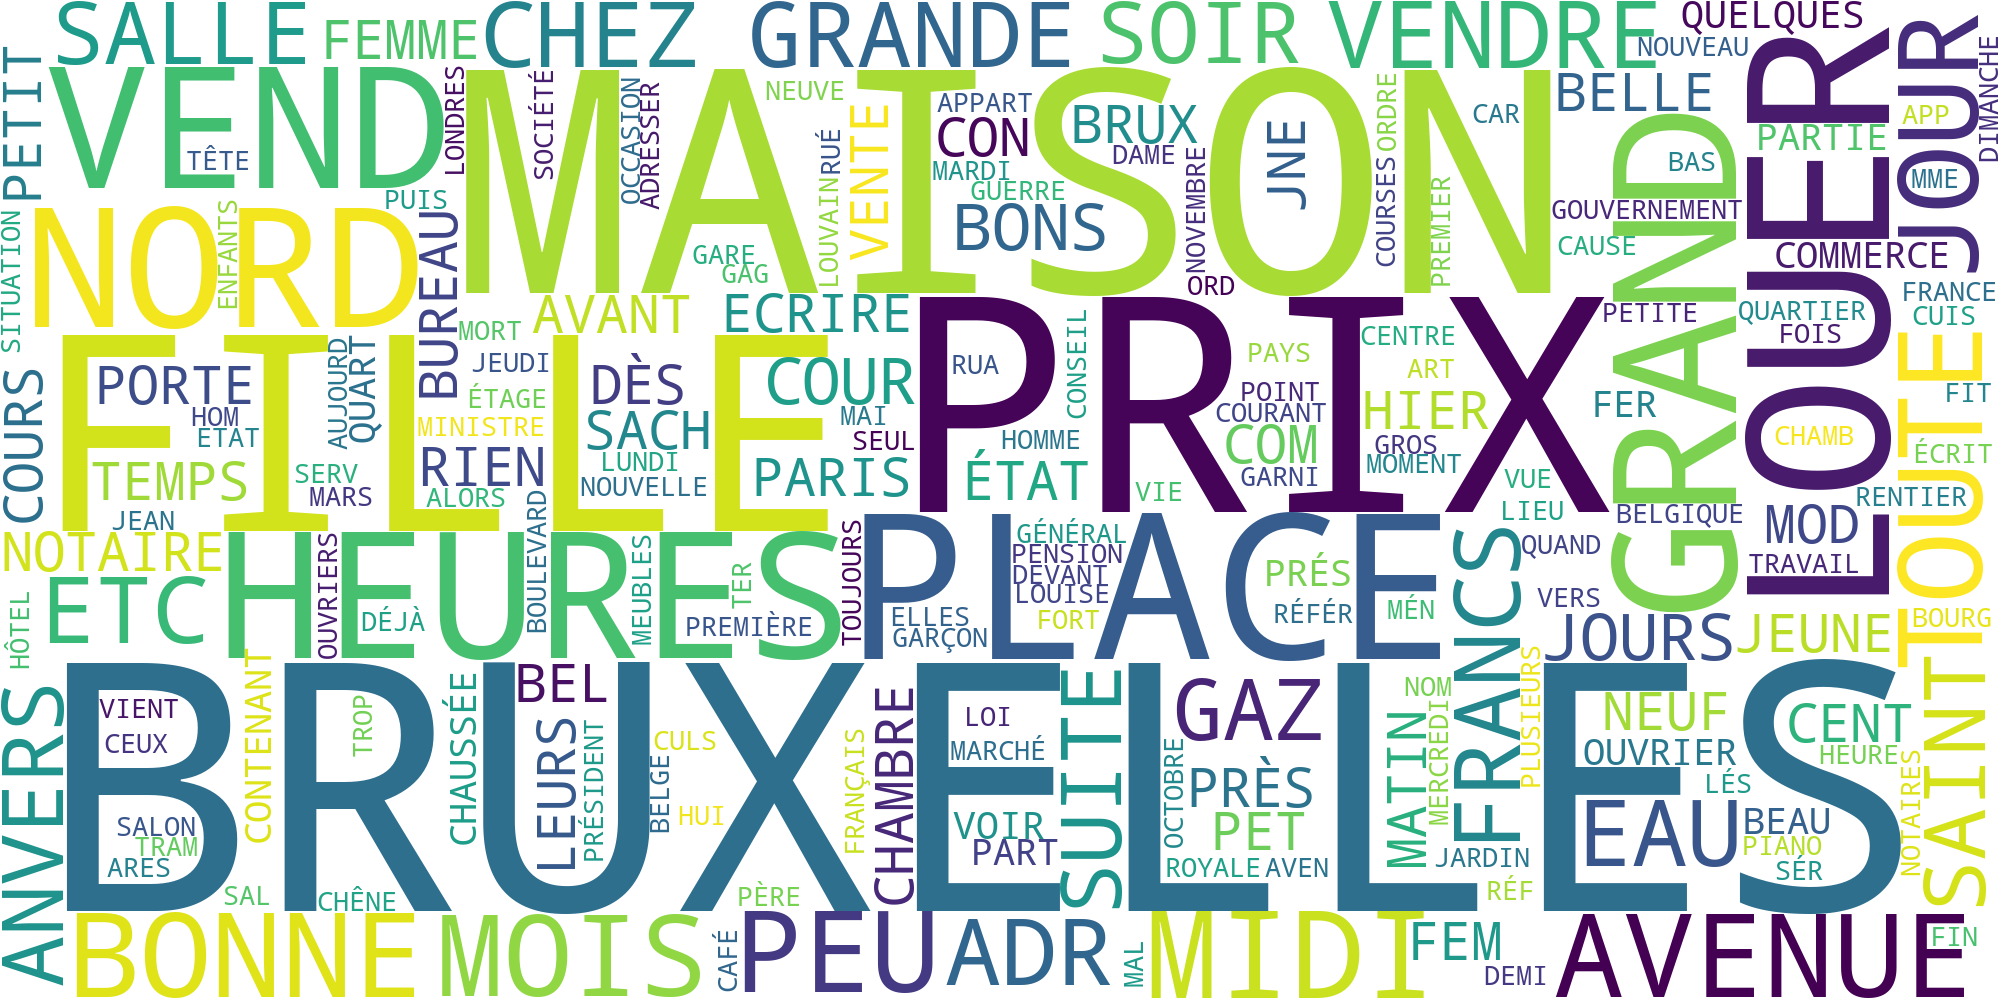

In [29]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))